# Laplace approximation on a real patient fiber field

Low-rank Laplace approximation of the posterior of `patient_map.ipynb`, centered at its MAP estimate (`map_patient.npy`). The posterior is approximated by $\mathcal N(m_\mathrm{MAP}, \Gamma)$ with $\Gamma^{-1} = \Gamma_0^{-1} + H$, where $\Gamma_0$ is the prior covariance and $H$ the Gauss-Newton Hessian of the data misfit at the MAP estimate. The dominant eigenpairs of $Hv = \lambda\Gamma_0^{-1}v$ give $\Gamma = \Gamma_0 - V D V^T$ with $D = \mathrm{diag}(\lambda_i/(1+\lambda_i))$.

The posterior must be the one the MAP estimate belongs to: the data and the prior mean are regenerated exactly as in `patient_map.ipynb` (same patient, observation settings, seeds and prior mean constant), and the loss is checked against the MAP estimate below. Change the settings in both notebooks together.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from ls_bayesian.lowrank.eigensolvers import RandomizedDoublePassSolver

from bayes_cep.laplace.builder import LaplaceBuilder, LaplaceSettings
from bayes_cep.mesh.geodesic import assemble_edge_length_graph, compute_graph_distances
from bayes_cep.mesh.interpolation import NearestNeighborInterpolationStrategy
from bayes_cep.mesh.io import load_pyvista_mesh
from bayes_cep.posterior.builder import PosteriorBuilder, PosteriorSettings
from bayes_cep.posterior.eikonal_map import EikonalParameterToSolutionMap
from bayes_cep.posterior.likelihood import LikelihoodSettings
from bayes_cep.posterior.prior import PriorParameters
from bayes_cep.preprocessing.angle_field import build_angle_field_from_fiber_field
from bayes_cep.preprocessing.synthetic_observations import (
    ObservationSamplingSettings,
    generate_synthetic_observations,
)
from bayes_cep.statistics.axial_error_metrics import compute_error_by_distance
from bayes_cep.statistics.axial_statistics import (
    compute_axial_data_diff,
    compute_axial_mean_and_variance,
    compute_standard_deviation_degrees,
    wrap_axial_angles,
)
from single_runs.reference import (
    NOISE_VARIANCE,
    NUM_OBSERVATIONS,
    OBSERVATION_SEED,
    reference_eikonal_settings,
)

pv.set_jupyter_backend("trame")

## Settings

Prior, observations and prior mean as in `patient_map.ipynb`. `NUM_EIGENVALUES` is the rank budget $k$; the randomized double-pass solver needs $2(k + p)$ Hessian products for oversampling $p$, each one a forward and an adjoint triangular solve. Eigenpairs with an eigenvalue at most `MINIMUM_EIGENVALUE` are dropped.

In [2]:
PATIENT_DIR = Path.cwd().parent / "example_data" / "raw"
MAP_PATH = Path.cwd() / "map_patient.npy"
PRIOR = PriorParameters(kappa=0.5, tau=0.5, seed=0)
OBSERVATIONS = ObservationSamplingSettings(
    num_observations=NUM_OBSERVATIONS, noise_variance=NOISE_VARIANCE, seed=OBSERVATION_SEED
)
MEAN_CONSTANT = None  # as in patient_map.ipynb: None scans for the constant that fits best

NUM_EIGENVALUES = 1000
OVERSAMPLING = 20
MINIMUM_EIGENVALUE = 1e-6
NUM_SAMPLES = 1000

## Data and MAP estimate

The ground truth is the patient field; the activation times are synthetic (forward-solved, sparsely sampled, noisy), as in `patient_map.ipynb`.

In [3]:
mesh = load_pyvista_mesh(PATIENT_DIR / "mesh.vtu")
basis_vectors = np.load(PATIENT_DIR / "basis_vecs.npy")
fiber_field = np.load(PATIENT_DIR / "fiber_field.npy")
eikonal_settings = reference_eikonal_settings()
interpolation_strategy = NearestNeighborInterpolationStrategy()
connectivity = mesh.cells.reshape(-1, 4)[:, 1:]

ground_truth = build_angle_field_from_fiber_field(mesh, fiber_field, basis_vectors)
forward_map = EikonalParameterToSolutionMap(
    mesh, basis_vectors, eikonal_settings, interpolation_strategy
)
observed_vertex_indices, observed_activation_times = generate_synthetic_observations(
    forward_map, ground_truth, OBSERVATIONS
)
if MEAN_CONSTANT is None:
    candidates = np.linspace(-np.pi / 2, np.pi / 2, 25, endpoint=False)
    misfits = [
        np.sum(
            (
                forward_map.evaluate_forward(np.full(mesh.n_points, constant))[observed_vertex_indices]
                - observed_activation_times
            )
            ** 2
        )
        for constant in candidates
    ]
    mean_constant = float(candidates[np.argmin(misfits)])
else:
    mean_constant = MEAN_CONSTANT
prior_mean = np.full(mesh.n_points, mean_constant)

map_estimate = np.load(MAP_PATH)
if map_estimate.shape != (mesh.n_points,):
    raise ValueError(f"MAP estimate has shape {map_estimate.shape}, expected ({mesh.n_points},)")
print(f"{mesh.n_points} vertices, {mesh.n_cells} triangles, {observed_vertex_indices.size} observed")
print(f"prior mean: constant {mean_constant:.2f} rad")

15820 vertices, 31375 triangles, 1000 observed
prior mean: constant 0.94 rad


## Posterior components

`PosteriorBuilder.build_components` returns the likelihood, the forward map and the prior uncomposed (the Hessian needs the first two); `build` gives the `LogPosterior` for the consistency check below.

In [4]:
posterior_builder = PosteriorBuilder(
    PosteriorSettings(
        mesh=mesh,
        basis_vectors=basis_vectors,
        prior_mean_vector=prior_mean,
        prior_parameters=PRIOR,
        eikonal_settings=eikonal_settings,
        likelihood_settings=LikelihoodSettings(
            num_vertices=mesh.n_points,
            observed_vertex_indices=observed_vertex_indices,
            data_vector=observed_activation_times,
            noise_variance=OBSERVATIONS.noise_variance,
        ),
    ),
    interpolation_strategy=interpolation_strategy,
)
components = posterior_builder.build_components()
log_posterior = posterior_builder.build()

# The MAP estimate belongs to this posterior if its loss is far below that of the prior mean
for name, field in (("MAP estimate", map_estimate), ("prior mean", prior_mean), ("patient field", ground_truth)):
    likelihood_cost = log_posterior.evaluate_likelihood_cost(field)
    prior_cost = log_posterior.evaluate_prior_cost(field)
    print(f"{name:<14} loss {likelihood_cost + prior_cost:>12.1f}  (likelihood {likelihood_cost:>10.1f}, prior {prior_cost:>10.1f})")

MAP estimate   loss        388.8  (likelihood      118.6, prior      270.2)
prior mean     loss    3697208.2  (likelihood  3697208.2, prior        0.0)
patient field  loss     124130.8  (likelihood      477.6, prior   123653.2)


## Low-rank approximation

Directions beyond the smallest kept eigenvalue are not corrected, so the variance there is the prior variance: check the spectrum before trusting the variance maps.

In [5]:
laplace_settings = LaplaceSettings(
    eigensolver=RandomizedDoublePassSolver(oversampling=OVERSAMPLING, seed=0),
    num_eigenvalues=NUM_EIGENVALUES,
    minimum_eigenvalue=MINIMUM_EIGENVALUE,
    sample_seed=0,
)
approximation = LaplaceBuilder(laplace_settings, components).build(map_estimate)
eigenvalues = approximation.eigenpairs.eigenvalues
eigenvectors = approximation.eigenpairs.eigenvectors

print(f"kept {eigenvalues.size} of {NUM_EIGENVALUES} eigenpairs")
print(f"eigenvalues from {eigenvalues[0]:.3e} down to {eigenvalues[-1]:.3e}")
print(f"number of eigenvalues above 1 (data-dominated): {int(np.sum(eigenvalues > 1.0))}")
print(f"log det(Gamma) - log det(Gamma_0): {approximation.gaussian.compute_log_determinant_ratio():.1f}")

kept 968 of 1000 eigenpairs
eigenvalues from 5.675e+05 down to 1.219e-01
number of eigenvalues above 1 (data-dominated): 877
log det(Gamma) - log det(Gamma_0): -3782.6


## Eigenvalue spectrum and convergence in the rank

The posterior variance along $v_i$ is reduced by the factor $1/(1+\lambda_i)$. If the smallest eigenvalue is still far above 1 (gray line), the rank is too low. The right panel is the exact mean variance reduction $\mathrm{diag}(V_k D_k V_k^T)$ of the first $k$ pairs; a curve still rising at the full rank means more pairs would reduce the variance further.

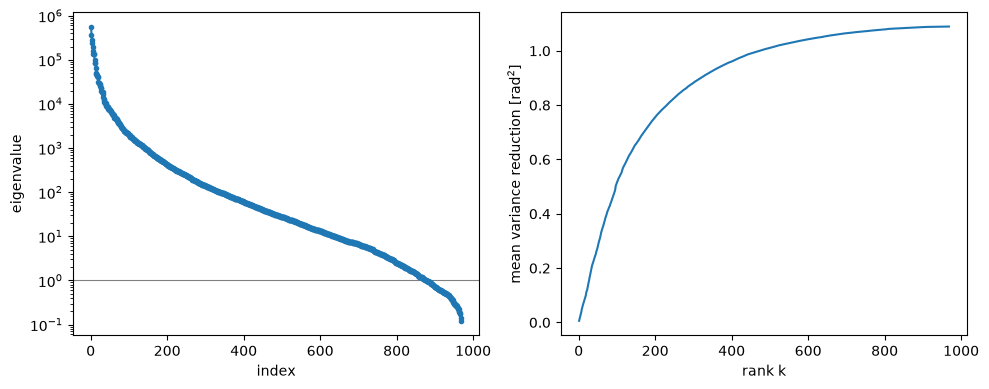

In [6]:
ranks = np.arange(1, eigenvalues.size + 1)
weights = eigenvalues / (1.0 + eigenvalues)
mean_variance_reduction = np.cumsum(np.mean(eigenvectors**2, axis=0) * weights)

fig, (spectrum_axis, reduction_axis) = plt.subplots(1, 2, figsize=(10, 4))
spectrum_axis.axhline(1.0, color="gray", linewidth=0.8)
spectrum_axis.semilogy(ranks, eigenvalues, marker=".")
spectrum_axis.set_xlabel("index")
spectrum_axis.set_ylabel("eigenvalue")
reduction_axis.plot(ranks, mean_variance_reduction)
reduction_axis.set_xlabel("rank k")
reduction_axis.set_ylabel("mean variance reduction [rad$^2$]")
fig.tight_layout()

## Samples and statistics

Samples are $m_\mathrm{MAP} + \hat\Gamma\xi$ with $\xi$ standard normal; their variance per vertex has a relative sampling error of about $\sqrt{2/N}$. The pointwise variance is that of the unwrapped Gaussian marginals, the axial one is wrapped modulo $\pi$ (as in the MCMC run).

In [7]:
samples = np.stack([approximation.gaussian.generate_sample() for _ in range(NUM_SAMPLES)])
laplace_variance = samples.var(axis=0, ddof=1)
laplace_axial_mean, laplace_axial_variance = compute_axial_mean_and_variance(samples)
laplace_std = compute_standard_deviation_degrees(laplace_variance)
laplace_axial_std = compute_standard_deviation_degrees(laplace_axial_variance)

print(f"pointwise std: mean {laplace_std.mean():.2f}, max {laplace_std.max():.2f} deg")
print(f"axial std:     mean {laplace_axial_std.mean():.2f}, max {laplace_axial_std.max():.2f} deg")

pointwise std: mean 28.32, max 87.90 deg
axial std:     mean 28.30, max 100.13 deg


## Mean and standard deviation on the mesh

The angle is axial, so it is plotted modulo $\pi$. Wrapped angles are shown per simplex (as the forward model sees the field): interpolating them over a cell would run through the whole colormap wherever the field crosses the seam at $\pm\pi/2$. The standard deviation is smooth and is shown per vertex.

In [8]:
vertex_to_simplex_matrix = interpolation_strategy.assemble_matrix(mesh.points, connectivity)
clim = (-np.pi / 2, np.pi / 2)
for name, values, cmap, limits in (
    ("ground truth (patient)", wrap_axial_angles(vertex_to_simplex_matrix @ ground_truth), "hsv", clim),
    ("Laplace mean (MAP)", wrap_axial_angles(vertex_to_simplex_matrix @ map_estimate), "hsv", clim),
):
    plot_mesh = mesh.copy()
    plot_mesh.cell_data["value"] = values
    plotter = pv.Plotter()
    plotter.add_mesh(plot_mesh, scalars="value", cmap=cmap, clim=limits)
    plotter.add_text(name)
    plotter.show()

plot_mesh = mesh.copy()
plot_mesh.point_data["std"] = laplace_std
plotter = pv.Plotter()
plotter.add_mesh(plot_mesh, scalars="std", cmap="viridis")
plotter.add_text("pointwise standard deviation [deg]")
plotter.show()

Widget(value='<iframe src="http://localhost:40175/index.html?ui=P_0x7f480cac63c0_0&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:40175/index.html?ui=P_0x7f480caee350_1&reconnect=auto" class="pyvi…

Widget(value='<iframe src="http://localhost:40175/index.html?ui=P_0x7f480c7f9a90_2&reconnect=auto" class="pyvi…

## Standard deviation vs. distance to the observations

Away from the data the prior decides, so the standard deviation should grow with the graph distance to the nearest observation towards the prior standard deviation.

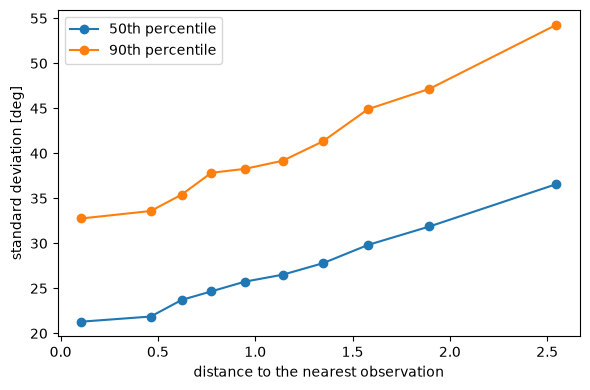

In [9]:
vertex_distances = compute_graph_distances(
    assemble_edge_length_graph(mesh.points, connectivity),
    observed_vertex_indices,
    min_over_sources=True,
)
distance_quantiles = (0.5, 0.9)
bin_distances, bin_quantiles = compute_error_by_distance(
    vertex_distances, laplace_std, num_bins=10, quantiles=distance_quantiles
)

fig, axis = plt.subplots(figsize=(6, 4))
for quantile, values in zip(distance_quantiles, bin_quantiles.T, strict=True):
    axis.plot(bin_distances, values, marker="o", label=f"{int(100 * quantile)}th percentile")
axis.set_xlabel("distance to the nearest observation")
axis.set_ylabel("standard deviation [deg]")
axis.legend()
fig.tight_layout()

## Calibration against the patient field

The patient field is known here, so the approximation can be checked: the standardized axial error $z = (m_\mathrm{MAP} - m_\mathrm{truth}) / \sigma$ should have unit spread if the uncertainty is honest. The error is axial (a shift by $\pi$ is no error), $\sigma$ the pointwise standard deviation. Fractions near 0.68 / 0.95 are calibrated; lower ones mean overconfidence (the Gaussian approximation misses the non-Gaussian posterior, or the MAP estimate sits in another branch).

within 1 sigma: 0.554 (Gaussian: 0.683)
within 2 sigma: 0.782 (Gaussian: 0.954)
within 3 sigma: 0.899 (Gaussian: 0.997)


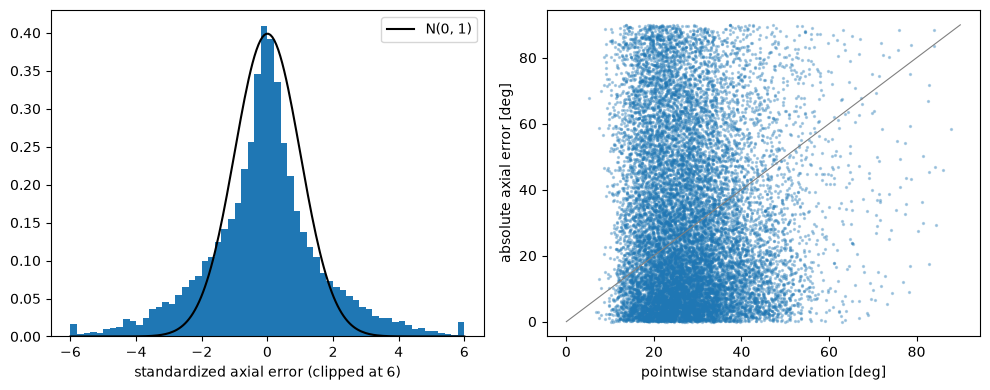

In [10]:
axial_error = compute_axial_data_diff(map_estimate, ground_truth)
standardized_error = axial_error / np.sqrt(laplace_variance)
for num_sigma, nominal in ((1, 0.683), (2, 0.954), (3, 0.997)):
    covered = np.mean(np.abs(standardized_error) <= num_sigma)
    print(f"within {num_sigma} sigma: {covered:.3f} (Gaussian: {nominal:.3f})")

fig, (histogram_axis, scatter_axis) = plt.subplots(1, 2, figsize=(10, 4))
histogram_axis.hist(np.clip(standardized_error, -6, 6), bins=60, density=True)
grid = np.linspace(-6, 6, 200)
histogram_axis.plot(grid, np.exp(-0.5 * grid**2) / np.sqrt(2 * np.pi), color="black", label="N(0, 1)")
histogram_axis.set_xlabel("standardized axial error (clipped at 6)")
histogram_axis.legend()
scatter_axis.scatter(laplace_std, np.degrees(np.abs(axial_error)), s=2, alpha=0.3)
limit = max(laplace_std.max(), np.degrees(np.abs(axial_error)).max())
scatter_axis.plot([0, limit], [0, limit], color="gray", linewidth=0.8)
scatter_axis.set_xlabel("pointwise standard deviation [deg]")
scatter_axis.set_ylabel("absolute axial error [deg]")
fig.tight_layout()